In [ ]:
#TODO: Importation des bibliothèques nécessaires
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical

In [ ]:
# TODO:Chargement et prétraitement des données CIFAR-10
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
#TODO: Normalisation des pixels entre 0 et 1
x_train, x_test = x_train / 255.0, x_test / 255.0  # Normalisation
# TODO: Conversion des étiquettes en one-hot encoding
y_train, y_test = to_categorical(y_train), to_categorical(y_test)

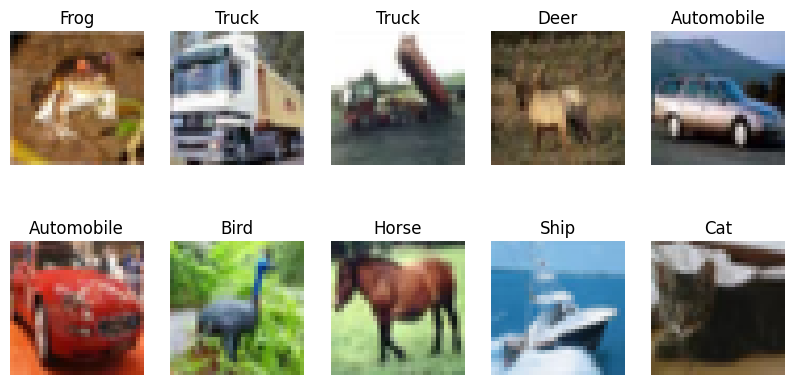

In [ ]:
import matplotlib.pyplot as plt
# TODO:Noms des classes
class_names = cifar10.class_names

# Affichage de quelques exemples avec leurs étiquettes
plt.figure(figsize=(10, 5))
 # TODO: Afficher 10 exemples
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])

    # Convert one-hot encoded label to its class index
    label = np.argmax(y_train[i])

    plt.title(class_names[label])
    plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
# TODO:Définition du modèle CNN
model = models.Sequential()
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(10, activation='softmax'))

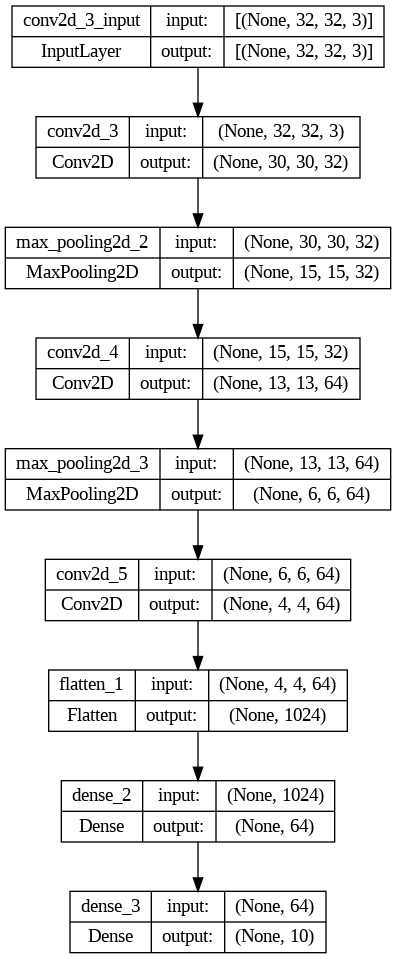

In [ ]:
from tensorflow.keras.utils import plot_model
# TODO:affichage et Enregistrement d'une image du modèle
plot_model(
     model,
     to_file='model.png',
     show_shapes=True,
     show_layer_names=True
)


In [ ]:
# TODO:Compilation du modèle
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [ ]:
from keras.src.callbacks import ModelCheckpoint

# TODO:Callback pour enregistrer le meilleur modèle
checkpoint_filepath = 'best_model.h5'
model_checkpoint = model_checkpoint = ModelCheckpoint(
    filepath=checkpoint_filepath,
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

In [ ]:
# TODO: Entraînement du modèle avec le callback ModelCheckpoint
history=model.fit(x_train, y_train, epochs=10, validation_split=0.2)


Epoch 1/10
938/938 [==============================] - ETA: 0s - loss: 1.6577 - accuracy: 0.3878
Epoch 1: val_accuracy improved from -inf to 0.46730, saving model to best_model.h5
938/938 [==============================] - 45s 47ms/step - loss: 1.6577 - accuracy: 0.3878 - val_loss: 1.4332 - val_accuracy: 0.4673
Epoch 2/10
  2/938 [..............................] - ETA: 1:02 - loss: 1.4409 - accuracy: 0.4688

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


937/938 [============================>.] - ETA: 0s - loss: 1.2916 - accuracy: 0.5358
Epoch 2: val_accuracy improved from 0.46730 to 0.55630, saving model to best_model.h5
938/938 [==============================] - 43s 45ms/step - loss: 1.2916 - accuracy: 0.5358 - val_loss: 1.2267 - val_accuracy: 0.5563
Epoch 3/10
938/938 [==============================] - ETA: 0s - loss: 1.1349 - accuracy: 0.5953
Epoch 3: val_accuracy improved from 0.55630 to 0.60810, saving model to best_model.h5
938/938 [==============================] - 40s 43ms/step - loss: 1.1349 - accuracy: 0.5953 - val_loss: 1.1042 - val_accuracy: 0.6081
Epoch 4/10
937/938 [============================>.] - ETA: 0s - loss: 1.0281 - accuracy: 0.6340
Epoch 4: val_accuracy improved from 0.60810 to 0.62680, saving model to best_model.h5
938/938 [==============================] - 50s 54ms/step - loss: 1.0278 - accuracy: 0.6340 - val_loss: 1.0587 - val_accuracy: 0.6268
Epoch 5/10
937/938 [============================>.] - ETA: 0s - lo

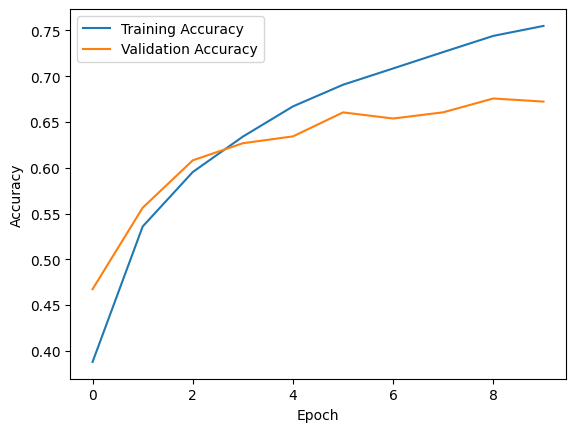

In [ ]:
# TODO:Affichage les courbes de l'historique d'entraînement
import matplotlib.pyplot as plt

# Accuracy curves
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss curves
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# TODO: Évaluation du modèle sur l'ensemble de test
from sklearn.metrics import accuracy_score
y_predict = model.predict(x_test)
print('Accuracy on test set:',accuracy_score(y_predict,y_test))

313/313 [==============================] - 5s 15ms/step - loss: 0.9495 - accuracy: 0.6772
Accuracy on test set: 0.6772000193595886


In [ ]:
# Sauvegarde du modèle
model.save('image_classifier_model.h5')

# **PARTIE TEST**

313/313 [==============================] - 4s 11ms/step


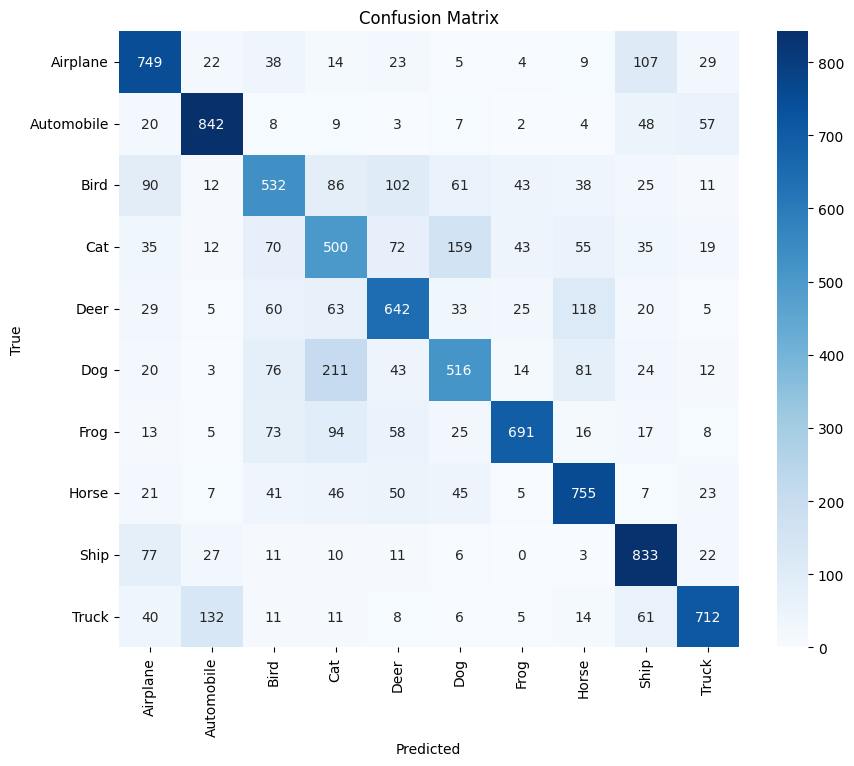

Classification Report:
               precision    recall  f1-score   support

    Airplane       0.68      0.75      0.72      1000
  Automobile       0.79      0.84      0.81      1000
        Bird       0.58      0.53      0.55      1000
         Cat       0.48      0.50      0.49      1000
        Deer       0.63      0.64      0.64      1000
         Dog       0.60      0.52      0.55      1000
        Frog       0.83      0.69      0.75      1000
       Horse       0.69      0.76      0.72      1000
        Ship       0.71      0.83      0.77      1000
       Truck       0.79      0.71      0.75      1000

    accuracy                           0.68     10000
   macro avg       0.68      0.68      0.68     10000
weighted avg       0.68      0.68      0.68     10000



In [ ]:
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Chargement et prétraitement des données CIFAR-10
(_, _), (x_test, y_test) = cifar10.load_data()

# Normalisation des pixels entre 0 et 1
x_test = x_test / 255.0

# Conversion des étiquettes en one-hot encoding
y_test = to_categorical(y_test)

# Chargement du modèle pré-entraîné
loaded_model = load_model('image_classifier_model.h5')

# Noms des classes
class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

# Évaluation du modèle sur l'ensemble de test
test_loss, test_accuracy = loaded_model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# Prédictions du modèle
y_pred = loaded_model.predict(x_test)

# Conversion des probabilités en indices de classes
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# Matrice de confusion
confusion_mtx = confusion_matrix(y_true_classes, y_pred_classes)

# Affichage de la matrice de confusion
plt.figure(figsize=(10, 8))

sns.heatmap(
    confusion_mtx,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

# Rapport de classification
print("Classification Report:")
print(
    classification_report(
        y_true_classes,
        y_pred_classes,
        target_names=class_names
    )
)